Comprueba que este Jupyter puede leer los CSV de /datalake/raw y escribir Parquet en HDFS (WebHDFS).


In [1]:
import os
import pandas as pd

# Dirección de HDFS por WebHDFS (viene de las variables de entorno del contenedor)
HOST = os.environ.get('HDFS_WEBHDFS_URL', 'http://namenode:9870').replace('http://', '')
OPT = {'user': os.environ.get('HDFS_USER', 'root')}   # usuario con el que se accede a HDFS
RAW = f'webhdfs://{HOST}/datalake/raw'
CLEAN = f'webhdfs://{HOST}/datalake/clean'
print(RAW)


webhdfs://namenode:9870/datalake/raw


**1. Lectura csv**

In [2]:
df = pd.read_csv(f"{RAW}/ventas_diarias_platos/01_ventas_diarias_platos.csv", sep=",")

**2. Primera muestra dataset**

Visualizamos una primera muestra para ir viendo qué tipo de cosas tendríamos que modificar, eliminar, corregir... ahor amismo ya podemos ver que hay fechas incorretas, formatos inválidos, columnas sin formato, columnas inservibles...

In [3]:
df.head(10)

,fecha,id_plato,precio_unidad,coste_unidad,unidades_vendidas,clientes_dia,nombre_plato_aux,franja,ciudad,moneda,categoria,valoracion,dificultad_elaboracion,popularidad,margen_unitario
0,22/02/2024,44,5.79,2.79,muchos,78.0,Pasta 44,cena,Madrid,EUR,postre,4.0,6.0,NaN,3.00
1,2024-07-18,46,21.84,8.91,34,36.0,Ensalada 46,cena,Sevilla,EUR,postre,4.3,4.0,0.9444,12.93
2,2024-06-07,80,7.68,2.62,4,73.0,Paella 80,comida,Sevilla,EUR,principal,4.8,9.0,0.0548,5.06
3,2023-11-16,51,21.92,9.90,11,50.0,Croquetas 51,cena,Sevilla,EUR,postre,4.4,4.0,0.2200,12.02
4,2023-11-06,9,26.0,11.01,11,40.0,Paella 9,terraza,Valencia,EUR,principal,5.0,7.0,0.2750,14.99
5,2024-06-26,70,13.43,6.39,35,48.0,Pulpo 70,cena,Madrid,EUR,entrante,4.6,6.0,0.7292,7.04
6,2025-07-12,67,7.48,4.31,37,40.0,Gazpacho 67,cena,Valencia,EUR,entrante,3.4,4.0,0.9250,3.17
7,11/08/2025,25,20.96,5.03,35,45.0,Tortilla 25,delivery,Sevilla,EUR,bebida,3.0,2.0,0.7778,15.93
8,2025-01-09,72,23.86,10.96,34,43.0,Tortilla 72,cena,Valencia,EUR,postre,4.4,3.0,0.7907,12.90
9,2023-02-17,14,22.72,10.10,14,60.0,Pulpo 14,cena,Sevilla,EUR,entrante,4.4,4.0,0.2333,12.62


**3. Dimensiones y tipos de datos**

Comprobamos el número de filas y columnas del dataset y los tipos de columnas

In [4]:
df.shape

(110500, 15)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110500 entries, 0 to 110499
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   fecha                   109735 non-null  object 
 1   id_plato                109762 non-null  object 
 2   precio_unidad           109791 non-null  object 
 3   coste_unidad            109761 non-null  float64
 4   unidades_vendidas       109710 non-null  object 
 5   clientes_dia            109739 non-null  float64
 6   nombre_plato_aux        110500 non-null  object 
 7   franja                  110500 non-null  object 
 8   ciudad                  110500 non-null  object 
 9   moneda                  110500 non-null  object 
 10  categoria               109762 non-null  object 
 11  valoracion              109762 non-null  float64
 12  dificultad_elaboracion  109762 non-null  float64
 13  popularidad             106403 non-null  float64
 14  margen_unitario     

Aquí ya podemos ver que hay muchas columnas sin tipo predefinido por lo que habría que añadir los tipos para que en nuevos datos no se pudiesen añadir datos erróneos,vacíos....

In [6]:
df.dtypes

fecha                      object
id_plato                   object
precio_unidad              object
coste_unidad              float64
unidades_vendidas          object
clientes_dia              float64
nombre_plato_aux           object
franja                     object
ciudad                     object
moneda                     object
categoria                  object
valoracion                float64
dificultad_elaboracion    float64
popularidad               float64
margen_unitario           float64
dtype: object

**4. Número de valores ausentes y duplicados**

Miramos el número de celdas vacías y los duplicados

In [7]:
df.isna().sum() #Miramos los vacíos

fecha                      765
id_plato                   738
precio_unidad              709
coste_unidad               739
unidades_vendidas          790
clientes_dia               761
nombre_plato_aux             0
franja                       0
ciudad                       0
moneda                       0
categoria                  738
valoracion                 738
dificultad_elaboracion     738
popularidad               4097
margen_unitario           1448
dtype: int64

In [8]:
df.duplicated().sum() #Miramos los duplicados

np.int64(500)

**5. Porcentaje de valores ausentes**

En este paso veremos el porcentaje de valores ausentes por columna, así sabemos donde tenemos más porcentaje


In [9]:
(df.isna().mean() * 100).round(2).sort_values(ascending=False)

popularidad               3.71
margen_unitario           1.31
unidades_vendidas         0.71
clientes_dia              0.69
fecha                     0.69
coste_unidad              0.67
id_plato                  0.67
valoracion                0.67
dificultad_elaboracion    0.67
categoria                 0.67
precio_unidad             0.64
nombre_plato_aux          0.00
moneda                    0.00
franja                    0.00
ciudad                    0.00
dtype: float64

**6. Porcentaje de filas duplicadas**

Ahora comprobamos el porcentaje de filas duplicadas.

In [10]:
(df.duplicated().mean() * 100).round(2)

np.float64(0.45)

In [11]:
df[df.duplicated(keep=False)].sort_values(
    by=df.columns.tolist()
).head(10)

,fecha,id_plato,precio_unidad,coste_unidad,unidades_vendidas,clientes_dia,nombre_plato_aux,franja,ciudad,moneda,categoria,valoracion,dificultad_elaboracion,popularidad,margen_unitario
385,08/04/2025,63,27.1,14.75,16,76.0,Ensalada 63,delivery,Valencia,EUR,entrante,3.6,3.0,0.2105,12.35
110385,08/04/2025,63,27.1,14.75,16,76.0,Ensalada 63,delivery,Valencia,EUR,entrante,3.6,3.0,0.2105,12.35
7,11/08/2025,25,20.96,5.03,35,45.0,Tortilla 25,delivery,Sevilla,EUR,bebida,3.0,2.0,0.7778,15.93
110007,11/08/2025,25,20.96,5.03,35,45.0,Tortilla 25,delivery,Sevilla,EUR,bebida,3.0,2.0,0.7778,15.93
473,16/11/2025,13,7.95,2.54,31,15.0,Pasta 13,cena,Madrid,EUR,bebida,3.8,2.0,2.0667,5.41
110473,16/11/2025,13,7.95,2.54,31,15.0,Pasta 13,cena,Madrid,EUR,bebida,3.8,2.0,2.0667,5.41
321,19/10/2025,31,4.58,1.65,32,32.0,Paella 31,cena,Madrid,EUR,principal,5.0,9.0,1.0000,2.93
110321,19/10/2025,31,4.58,1.65,32,32.0,Paella 31,cena,Madrid,EUR,principal,5.0,9.0,1.0000,2.93
126,2023-01-01,61,27.44,14.39,35,63.0,Paella 61,comida,Valencia,EUR,postre,4.0,6.0,0.5556,13.05
110126,2023-01-01,61,27.44,14.39,35,63.0,Paella 61,comida,Valencia,EUR,postre,4.0,6.0,0.5556,13.05


**7. Generamos df_eda**
Ahora creamos df_eda para quitar las 500 filas duplicadas que hemos encontrado, sin eliminar del original, por si acaso.

In [12]:
df_eda = df.drop_duplicates().copy()

print(f"Filas originales: {len(df)}")
print(f"Filas tras quitar duplicados: {len(df_eda)}")
print(f"Duplicados restantes: {df_eda.duplicated().sum()}")

Filas originales: 110500
Filas tras quitar duplicados: 110000
Duplicados restantes: 0


Ahora vemos como han bajado las filas del dataframe y que nos quedan 0 duplicados restantes. De ahora en adelante usaremos df_eda para seguir con el análisis


**8. Valores vacíos**

Ahora buscamos los vacíos por columna

In [13]:
df_eda.isna().sum().sort_values(ascending=False)

popularidad               4077
margen_unitario           1444
unidades_vendidas          786
fecha                      761
clientes_dia               759
id_plato                   737
categoria                  737
valoracion                 737
dificultad_elaboracion     737
coste_unidad               735
precio_unidad              709
nombre_plato_aux             0
moneda                       0
franja                       0
ciudad                       0
dtype: int64

**9. Porcentaje de valores vacíos**

In [14]:
porcentaje_nulos = (df_eda.isna().mean() * 100).round(2)

resumen_nulos = pd.DataFrame({
    "valores_ausentes": df_eda.isna().sum(),
    "porcentaje": porcentaje_nulos
}).sort_values("porcentaje", ascending=False)

resumen_nulos

,valores_ausentes,porcentaje
popularidad,4077,3.71
margen_unitario,1444,1.31
unidades_vendidas,786,0.71
clientes_dia,759,0.69
fecha,761,0.69
coste_unidad,735,0.67
id_plato,737,0.67
valoracion,737,0.67
dificultad_elaboracion,737,0.67
categoria,737,0.67


In [15]:
filas_con_nulos = df_eda.isna().any(axis=1).sum()
print(f"Filas con al menos un valor ausente: {filas_con_nulos} de {len(df_eda)}")

Filas con al menos un valor ausente: 6946 de 110000


**10. Tipos de datos y valores distintos**

Este código lo usamos para localizar los textos que impiden interpretar precios y unidades como números

In [16]:
resumen_columnas = pd.DataFrame({
    "tipo": df_eda.dtypes,
    "valores_distintos": df_eda.nunique(dropna=True),
    "valores_ausentes": df_eda.isna().sum()
})

resumen_columnas

,tipo,valores_distintos,valores_ausentes
fecha,object,2008,761
id_plato,object,160,737
precio_unidad,object,2402,709
coste_unidad,float64,1537,735
unidades_vendidas,object,95,786
clientes_dia,float64,129,759
nombre_plato_aux,object,800,0
franja,object,4,0
ciudad,object,3,0
moneda,object,1,0


**11. Revisión de columnas numéricas guardadas como texto**

Primero miramos en las columnas que deberían ser numéricas 

In [17]:
for columna in ["precio_unidad", "unidades_vendidas"]:
    valores = df_eda[columna].dropna().astype(str).str.strip()
    conversion = pd.to_numeric(
        valores.str.replace(",", ".", regex=False),
        errors="coerce"
    )

    print(f"\n{columna}:")
    display(valores[conversion.isna()].value_counts().head(20))


precio_unidad:


precio_unidad
12,5 €    1358
Name: count, dtype: int64


unidades_vendidas:


unidades_vendidas
muchos    1351
Name: count, dtype: int64

In [18]:
columnas_revisar = [
    "id_plato", "categoria", "valoracion", "dificultad_elaboracion"
]

df_eda[columnas_revisar].isna().sum(axis=1).value_counts().sort_index()

0    109263
4       737
Name: count, dtype: int64

Ya encontramos los casos que no se podían interpretar como números:
- precio_unidad: "12,5 €" aparece 1.358 veces.
- unidades_vendidas: "muchos" aparece 1.351 veces.
- En 737 filas faltan a la vez id_plato, categoria, valoracion y dificultad_elaboracion;

Seguimos conservando el dataset original. 

In [19]:
# Convertimos el precio a número: vamos a quitar el signo de la moneda (€) y cambiamos la coma por punto.
precio_limpio = (
    df_eda["precio_unidad"]
    .astype("string")
    .str.replace("€", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)
df_eda["precio_unidad_num"] = pd.to_numeric(
    precio_limpio,
    errors="coerce"
)
# Vamos a vaciar donde el valor es "muchos" 
unidades_limpias = (
    df_eda["unidades_vendidas"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({"muchos": pd.NA})
)
df_eda["unidades_vendidas_num"] = pd.to_numeric(
    unidades_limpias,
    errors="coerce"
)

Comprobamos los cambios realizados

In [20]:
df_eda[[
    "precio_unidad", "precio_unidad_num",
    "unidades_vendidas", "unidades_vendidas_num"
]].head(5)

,precio_unidad,precio_unidad_num,unidades_vendidas,unidades_vendidas_num
0,5.79,5.79,muchos,<NA>
1,21.84,21.84,34,34
2,7.68,7.68,4,4
3,21.92,21.92,11,11
4,26.0,26.0,11,11


Revisamos si ha habido valores que no haya podido convertir

In [21]:
df_eda[["precio_unidad_num", "unidades_vendidas_num"]].isna().sum()

precio_unidad_num         709
unidades_vendidas_num    2137
dtype: int64

Creamos en el dataframe del EDA una columna nueva para interpretar las fechas y conservar la original, por si acaso

In [22]:
fechas = df_eda["fecha"].astype("string").str.strip()

fecha_dmy = pd.to_datetime(
    fechas,
    format="%d/%m/%Y",
    errors="coerce"
)

fecha_iso = pd.to_datetime(
    fechas,
    format="%Y-%m-%d",
    errors="coerce"
)

df_eda["fecha_dt"] = fecha_dmy.fillna(fecha_iso)

Comprobamos si hay alguna fecha que no hemos podido interpretar

In [23]:
fallos_fecha = df_eda[
    df_eda["fecha"].notna() & df_eda["fecha_dt"].isna()
]

print(f"Fechas originales ausentes: {df_eda['fecha'].isna().sum()}")
print(f"Fechas no interpretadas: {len(fallos_fecha)}")

fallos_fecha["fecha"].value_counts().head(20)

Fechas originales ausentes: 761
Fechas no interpretadas: 0


Series([], Name: count, dtype: int64)

Creo columna de fecha_formateada, para ponerlo como se ha decidido en el equipo

In [24]:
df_eda["fecha_formateada"] = df_eda["fecha_dt"].dt.strftime("%d-%m-%Y")

Comprobamos el resultado, si nos lo formatea correctamente. Las columnas que mostramos son la fecha original, la fecha interpretada con los guiones, y por último la columna con el dato ya formateado.

In [25]:
df_eda[["fecha", "fecha_dt", "fecha_formateada"]].head(10)

,fecha,fecha_dt,fecha_formateada
0,22/02/2024,2024-02-22,22-02-2024
1,2024-07-18,2024-07-18,18-07-2024
2,2024-06-07,2024-06-07,07-06-2024
3,2023-11-16,2023-11-16,16-11-2023
4,2023-11-06,2023-11-06,06-11-2023
5,2024-06-26,2024-06-26,26-06-2024
6,2025-07-12,2025-07-12,12-07-2025
7,11/08/2025,2025-08-11,11-08-2025
8,2025-01-09,2025-01-09,09-01-2025
9,2023-02-17,2023-02-17,17-02-2023


**12. Estadísticas de variables numéricas**

Para ello sacamos la media, la desviación... Hacemos esto para revisar si tenemos outliers o anomalías

In [26]:
df_eda.select_dtypes(include="number").describe().T

,count,mean,std,min,25%,50%,75%,max
coste_unidad,109265.0,6.097721,3.324516,0.74,3.43,5.5,8.3,16.21
clientes_dia,109241.0,47.593138,21.536227,0.0,32.0,48.0,63.0,133.0
valoracion,109263.0,3.95467,0.469704,3.0,3.6,4.0,4.2,5.0
dificultad_elaboracion,109263.0,4.422632,2.186709,1.0,3.0,4.0,6.0,10.0
popularidad,105923.0,0.764225,1.626643,0.0,0.2418,0.4909,0.8438,71.0
margen_unitario,108556.0,9.892306,4.743306,-3.4,5.97,9.54,13.24,22.92
precio_unidad_num,109291.0,15.989699,6.905627,4.0,10.12,15.88,22.0,28.0
unidades_vendidas_num,107863.0,24.196675,15.759582,0.0,12.0,24.0,35.0,105.0


**13. Revisión de outliers**

La tabla muestra algunos valores que vamos a revisar antes de sacar conclusiones:
- clientes_dia tiene un mínimo de 0.
- popularidad llega a 71, aunque el 75 % de los valores está por debajo de 0,844. Hay valores altos que podrían ser outliers.
- margen_unitario tiene un mínimo de −3,4. Puede indicar ventas por debajo del coste, o un dato incorrecto.

In [27]:
columnas = [
    "clientes_dia",
    "popularidad",
    "margen_unitario",
    "precio_unidad_num",
    "unidades_vendidas_num"
]

for columna in columnas:
    print(f"\n{columna}")
    display(
        pd.concat([
            df_eda[columna].nsmallest(5),
            df_eda[columna].nlargest(5)
        ])
    )


clientes_dia


34          0.0
159         0.0
350         0.0
369         0.0
530         0.0
54965     133.0
39488     131.0
22492     130.0
101187    127.0
102256    125.0
Name: clientes_dia, dtype: float64


popularidad


30         0.0
45         0.0
66         0.0
83         0.0
125        0.0
23766     71.0
26011     62.0
79850     59.0
27725     56.0
108509    56.0
Name: popularidad, dtype: float64


margen_unitario


17879    -3.40
76710    -3.11
69764    -2.99
1275     -2.44
84093    -2.43
71095    22.92
6542     22.83
32652    22.83
33662    22.83
49083    22.83
Name: margen_unitario, dtype: float64


precio_unidad_num


3884      4.0
4598      4.0
17799     4.0
18769     4.0
34925     4.0
1959     28.0
3373     28.0
15988    28.0
26305    28.0
27470    28.0
Name: precio_unidad_num, dtype: Float64


unidades_vendidas_num


30         0
45         0
66         0
83         0
125        0
65940    105
9959      93
78738     92
92176     92
72623     91
Name: unidades_vendidas_num, dtype: Int64

Vistos los resultados, vamos a revisar otra vez popularidad y margen unitario. Vamos a ver los 5 valores más altos de cada una

In [28]:
for columna in ["popularidad", "margen_unitario"]:
    print(f"\nCinco valores más altos de {columna}")
    display(
        df_eda.loc[
            df_eda[columna].nlargest(5).index
        ]
    )


Cinco valores más altos de popularidad


,fecha,id_plato,precio_unidad,coste_unidad,unidades_vendidas,clientes_dia,nombre_plato_aux,franja,ciudad,moneda,categoria,valoracion,dificultad_elaboracion,popularidad,margen_unitario,precio_unidad_num,unidades_vendidas_num,fecha_dt,fecha_formateada
23766,2023-09-27,24,19.53,7.45,71,1.0,Sopa 24,delivery,Sevilla,EUR,bebida,3.2,2.0,71.0,12.08,19.53,71,2023-09-27,27-09-2023
26011,2024-07-23,58,13.12,2.56,62,1.0,Pasta 58,cena,Valencia,EUR,principal,4.7,7.0,62.0,10.56,13.12,62,2024-07-23,23-07-2024
79850,2024-11-11,11,7.41,3.73,59,1.0,Tarta queso 11,terraza,Sevilla,EUR,entrante,3.6,1.0,59.0,3.68,7.41,59,2024-11-11,11-11-2024
27725,2024-10-24,49,9.13,4.41,56,1.0,Sopa 49,terraza,Madrid,EUR,bebida,3.7,1.0,56.0,4.72,9.13,56,2024-10-24,24-10-2024
108509,2023-08-27,1,23.04,10.16,56,1.0,Tarta queso 1,comida,Valencia,EUR,entrante,4.0,4.0,56.0,12.88,23.04,56,2023-08-27,27-08-2023



Cinco valores más altos de margen_unitario


,fecha,id_plato,precio_unidad,coste_unidad,unidades_vendidas,clientes_dia,nombre_plato_aux,franja,ciudad,moneda,categoria,valoracion,dificultad_elaboracion,popularidad,margen_unitario,precio_unidad_num,unidades_vendidas_num,fecha_dt,fecha_formateada
71095,2023-09-26,47,27.97,5.05,19,17.0,Paella 47,delivery,Valencia,EUR,entrante,4.0,1.0,1.1176,22.92,27.97,19,2023-09-26,26-09-2023
6542,2025-06-22,28,27.85,5.02,13,42.0,Pasta 28,terraza,Sevilla,EUR,principal,3.3,6.0,0.3095,22.83,27.85,13,2025-06-22,22-06-2025
32652,2024-09-12,50,27.94,5.11,29,17.0,Croquetas 50,delivery,Valencia,EUR,bebida,3.9,2.0,1.7059,22.83,27.94,29,2024-09-12,12-09-2024
33662,2024-07-14,18,27.98,5.15,31,28.0,Tortilla 18,comida,Madrid,EUR,entrante,4.0,2.0,1.1071,22.83,27.98,31,2024-07-14,14-07-2024
49083,2025-07-23,22,27.91,5.08,22,56.0,Pulpo 22,comida,Sevilla,EUR,postre,4.4,6.0,0.3929,22.83,27.91,22,2025-07-23,23-07-2025


Parece que pueden ser valores válidos, pero para cerciorarnos vamos a comprobar si coinciden en general

In [29]:
comparacion = df_eda[["popularidad", "unidades_vendidas_num"]].dropna()

print(f"Filas comparables: {len(comparacion)}")
print(
    "Porcentaje donde popularidad = unidades vendidas:",
    (comparacion["popularidad"] == comparacion["unidades_vendidas_num"]).mean() * 100
)

Filas comparables: 105923
Porcentaje donde popularidad = unidades vendidas: 8.989549012018164


In [30]:
comparacion[
    comparacion["popularidad"] != comparacion["unidades_vendidas_num"]
].head(10)



,popularidad,unidades_vendidas_num
1,0.9444,34
2,0.0548,4
3,0.2200,11
4,0.2750,11
5,0.7292,35
6,0.9250,37
7,0.7778,35
8,0.7907,34
9,0.2333,14
10,1.1860,51


In [31]:
df_eda["popularidad"].describe(
    percentiles=[.90, .95, .99, .995]
)


count    105923.000000
mean          0.764225
std           1.626643
min           0.000000
50%           0.490900
90%           1.413800
95%           2.045500
99%           5.452278
99.5%         8.625000
max          71.000000
Name: popularidad, dtype: float64

In [32]:
(df_eda["popularidad"] > 1).sum()

np.int64(19436)

In [33]:
import numpy as np
denominador = df_eda["clientes_dia"].replace(0, float("nan"))
ratio = df_eda["unidades_vendidas_num"] / denominador

comparacion = pd.DataFrame({
    "popularidad": df_eda["popularidad"],
    "ventas_por_cliente": ratio
}).dropna()

coinciden = np.isclose(
    comparacion["popularidad"],
    comparacion["ventas_por_cliente"],
    rtol=1e-3,
    atol=1e-4
)

print(f"Casos comparables: {len(comparacion)}")
print(f"Coincidencia con ventas/clientes: {coinciden.mean():.2%}")

comparacion.loc[~coinciden].head(10)

Casos comparables: 105923
Coincidencia con ventas/clientes: 100.00%


,popularidad,ventas_por_cliente


Ya hemos comprobado que popularidad y ventas por cliente coinciden 100% por lo que no tiene errores o anomalías

**14. Variables categóricas**

Primero buscamos cuántos registros hay en cada categoría,  incluidos los vacíos.

In [34]:
for columna in ["franja", "ciudad", "categoria", "moneda"]:
    print(f"\nFrecuencias de {columna}:")
    display(df_eda[columna].value_counts(dropna=False))


Frecuencias de franja:


franja
delivery    27568
comida      27563
cena        27547
terraza     27322
Name: count, dtype: int64


Frecuencias de ciudad:


ciudad
Valencia    36850
Sevilla     36609
Madrid      36541
Name: count, dtype: int64


Frecuencias de categoria:


categoria
principal    37004
entrante     34253
postre       21656
bebida       16350
NaN            737
Name: count, dtype: int64


Frecuencias de moneda:


moneda
EUR    110000
Name: count, dtype: int64

**15. Gráficos de variables categóricas**

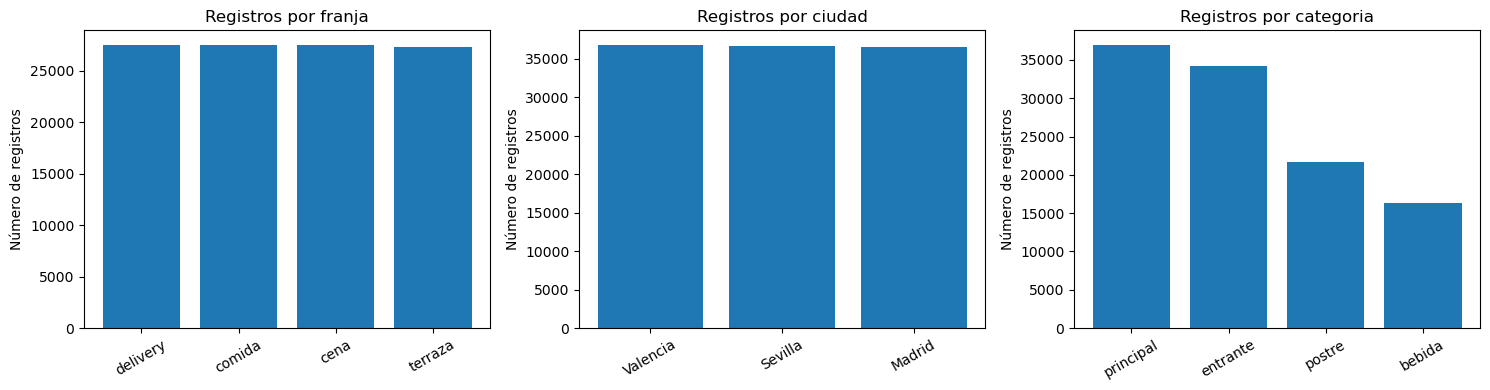

In [35]:
import matplotlib.pyplot as plt

columnas = ["franja", "ciudad", "categoria"]

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

for ax, columna in zip(ejes, columnas):
    frecuencias = df_eda[columna].value_counts(dropna=True)
    ax.bar(frecuencias.index.astype(str), frecuencias.values)
    ax.set_title(f"Registros por {columna}")
    ax.set_ylabel("Número de registros")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**16. Ventas por categoría**

In [36]:
ventas_categoria = (
    df_eda.groupby("categoria", dropna=False)["unidades_vendidas_num"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

ventas_categoria

,count,mean,median
categoria,,,
postre,21248,24.249153,24.0
entrante,33597,24.235854,24.0
bebida,16011,24.214228,24.0
principal,36277,24.141908,23.0
NaN,730,23.20274,22.0


El promedio de unidades vendidas es muy parecido entre las categorías conocidas: ronda las 24,1–24,2 unidades, y la mediana es de 23 o 24. En estos datos, la categoría no parece marcar una diferencia clara en las ventas medias.

Vamos a seguir comparando el margen unitario por categoría.

In [37]:
margen_categoria = (
    df_eda.groupby("categoria", dropna=False)["margen_unitario"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

margen_categoria

,count,mean,median
categoria,,,
entrante,33796,9.925059,9.56
principal,36505,9.905590,9.54
postre,21376,9.862605,9.54
bebida,16142,9.849980,9.49
NaN,737,9.520828,9.15


El margen unitario medio también es bastante parecido entre categorías: aproximadamente 9,85–9,93. bebida tiene el promedio algo menor (9,85), y los registros sin categoría, 9,52. Las medianas de las categorías conocidas están entre 9,49 y 9,56, así que las diferencias observadas son pequeñas.

Comparamos ahora el margen por franja.

In [38]:
margen_franja = (
    df_eda.groupby("franja")["margen_unitario"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

margen_franja

,count,mean,median
franja,,,
delivery,27222,9.925047,9.56
comida,27207,9.913999,9.58
cena,27185,9.892366,9.55
terraza,26942,9.837257,9.48


El margen medio es muy parecido entre franjas: va de 9,84 en terraza a 9,93 en delivery. La diferencia es pequeña, así que por ahora no parece haber un cambio destacado del margen según la franja.

Ahora veremos si las unidades vendidas varían por franja.

In [39]:
ventas_franja = (
    df_eda.groupby("franja")["unidades_vendidas_num"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

ventas_franja

,count,mean,median
franja,,,
cena,26990,24.299444,24.0
delivery,27037,24.207604,24.0
comida,27012,24.145565,23.0
terraza,26824,24.133724,23.0


Las unidades vendidas también son muy similares entre franjas: las medias van de 24,13 a 24,30 y las medianas de 23 a 24.

Realizamos la misma comparación por ciudad en vez de por franja.

In [40]:
ventas_ciudad = (
    df_eda.groupby("ciudad")["unidades_vendidas_num"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

ventas_ciudad

,count,mean,median
ciudad,,,
Valencia,36124,24.288672,24.0
Madrid,35837,24.162904,24.0
Sevilla,35902,24.13782,23.0


Las medias de unidades vendidas por ciudad son casi iguales: 24,29 en Valencia, 24,16 en Madrid y 24,14 en Sevilla.

Ahora miraremos si algunas variables numéricas se "mueven" juntas. Usaremos las ventas numéricas, el precio, el coste, los clientes, la valoración y la dificultad. Dejamos fuera margen_unitario y popularidad porque parece que salen de otras variables y podrían producir relaciones redundantes.

La correlación mide la tendencia a variar dos columnas juntas.

In [41]:
columnas_corr = [
    "precio_unidad_num",
    "coste_unidad",
    "unidades_vendidas_num",
    "clientes_dia",
    "valoracion",
    "dificultad_elaboracion"
]

correlaciones = df_eda[columnas_corr].corr()
correlaciones.round(2)

,precio_unidad_num,coste_unidad,unidades_vendidas_num,clientes_dia,valoracion,dificultad_elaboracion
precio_unidad_num,1.00,0.79,-0.0,0.0,0.00,-0.00
coste_unidad,0.79,1.00,-0.0,0.0,0.00,-0.00
unidades_vendidas_num,-0.00,-0.00,1.0,-0.0,0.00,-0.00
clientes_dia,0.00,0.00,-0.0,1.0,0.00,0.00
valoracion,0.00,0.00,0.0,0.0,1.00,0.56
dificultad_elaboracion,-0.00,-0.00,-0.0,0.0,0.56,1.00


Aquí podemos ver dos relaciones a destacar:

- Precio y coste tienen una correlación positiva alta (0,79): los platos con mayor coste tienden a tener mayor precio.
- Valoración y dificultad de elaboración tienen una correlación positiva moderada (0,56): las puntuaciones más altas de dificultad tienden a asociarse con valoraciones más altas.

El  resto de correlaciones salen prácticamente a 0 esto significa que son relaciones lineales.

Lo miramos con gráficos para ver y comprobar esto visualmente:

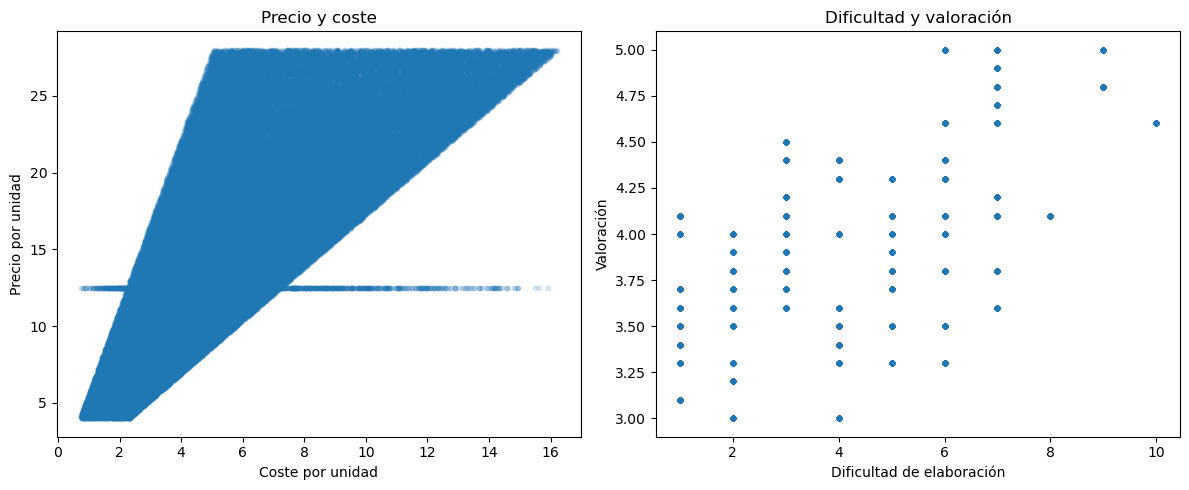

In [42]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

ejes[0].scatter(
    df_eda["coste_unidad"],
    df_eda["precio_unidad_num"],
    alpha=0.15,
    s=10
)
ejes[0].set_title("Precio y coste")
ejes[0].set_xlabel("Coste por unidad")
ejes[0].set_ylabel("Precio por unidad")

ejes[1].scatter(
    df_eda["dificultad_elaboracion"],
    df_eda["valoracion"],
    alpha=0.15,
    s=10
)
ejes[1].set_title("Dificultad y valoración")
ejes[1].set_xlabel("Dificultad de elaboración")
ejes[1].set_ylabel("Valoración")

plt.tight_layout()
plt.show()

El primer gráfico, de precio y coste nos muestra una tendencia ascendente, aunque los puntos se solapan mucho.

También destaca una línea horizontal aproximadamente en 12.5€, hay muchos registros con ese precio.

El gráfico de dificultad y valoración muestra una tendencia con variación, pero ascendente en general. Vamos a comprobar si ese precio que tanto se repite es especialmente frecuente:

In [43]:
(df_eda["precio_unidad_num"] == 12.5).sum()

np.int64(1393)

In [44]:
df_eda["precio_unidad_num"].value_counts().head(10)

precio_unidad_num
12.5     1393
11.05      68
10.55      68
25.98      68
22.63      66
6.73       65
24.29      64
13.89      64
7.35       64
15.79      64
Name: count, dtype: Int64

Con este cálculo podemos ver que si hay una cantidad excepcional con ese precio comparando con otros, pero podría ser un precio usado por varios platos, por lo que vamos a ver si es de varios platos o solo de uno.

In [45]:
filas_125 = df_eda[df_eda["precio_unidad_num"] == 12.5]

print(f"Registros con precio 12,5: {len(filas_125)}")
print(f"IDs de plato distintos: {filas_125['id_plato'].nunique()}")
print(f"Nombres de plato distintos: {filas_125['nombre_plato_aux'].nunique()}")

filas_125["nombre_plato_aux"].value_counts().head(10)

Registros con precio 12,5: 1393
IDs de plato distintos: 97
Nombres de plato distintos: 659


nombre_plato_aux
Pasta 78          7
Tarta queso 76    6
Sopa 20           6
Sopa 47           6
Pasta 27          6
Pasta 55          6
Tarta queso 55    6
Paella 2          5
Paella 6          5
Ensalada 78       5
Name: count, dtype: int64

El precio de 12,5 aparece en 1.393 registros, repartidos entre 97 IDs y 659 nombres de plato. No parece concentrado en un único plato, por lo que no sería un error, es un precio recurrente.

**17. Evolución mensual**

In [46]:
mensual = (
    df_eda.dropna(subset=["fecha_dt"])
    .groupby(pd.Grouper(key="fecha_dt", freq="MS"))
    .agg(
        registros=("fecha_dt", "size"),
        unidades_vendidas=("unidades_vendidas_num", "sum"),
        margen_medio=("margen_unitario", "mean")
    )
)

mensual

,registros,unidades_vendidas,margen_medio
fecha_dt,,,
2023-01-01,3033,72887,10.081923
2023-02-01,2737,65659,9.828726
2023-03-01,3089,73031,9.916304
2023-04-01,2998,70267,9.910102
2023-05-01,3105,74274,9.867259
2023-06-01,2992,69389,9.856438
2023-07-01,3038,70803,9.999903
2023-08-01,3118,74112,9.845190
2023-09-01,2956,69468,9.892906


La tabla cubre 36 meses, de enero de 2023 a diciembre de 2025, sin meses ausentes. El número de registros mensuales se mantiene bastante estable, alrededor de 2.700–3.250.

Antes de modificar, vamos a comprobar los valores vacíos que podemos recuperar con la fórmula de unidades_vendidas_num / clientes_dia

In [47]:
denominador = df_eda["clientes_dia"].where(df_eda["clientes_dia"] > 0)

popularidad_calculada = (
    df_eda["unidades_vendidas_num"] / denominador
)

recuperables = (
    df_eda["popularidad"].isna()
    & popularidad_calculada.notna()
)

print("Popularidad ausente:", df_eda["popularidad"].isna().sum())
print("Recuperable con ventas/clientes:", recuperables.sum())
print("Restante para rellenar con la media:",
      df_eda["popularidad"].isna().sum() - recuperables.sum())

Popularidad ausente: 4077
Recuperable con ventas/clientes: 0
Restante para rellenar con la media: 4077


Ya vemos que no hay ningún registro recuperable por lo que damos por acabado el análisis y empezaremos con la limpieza. 

**18. Limpieza de datos**

Creamos un dataframe limpio. Aplicaremos la mediana a precio y coste, y la media a las demás columnas numéricas del análisis exploratorio que hemos realizado. Convertimos unidades_vendidas_num a decimal porque al imputar la media

In [48]:
df_limpio = df_eda.copy()

# Precios: mediana
for columna in ["precio_unidad_num", "coste_unidad"]:
    mediana = df_limpio[columna].median()
    df_limpio[columna] = df_limpio[columna].fillna(mediana)

# Variables numéricas: media
columnas_media = [
    "unidades_vendidas_num",
    "clientes_dia",
    "margen_unitario",
    "valoracion",
    "dificultad_elaboracion",
    "popularidad"
]

for columna in columnas_media:
    df_limpio[columna] = df_limpio[columna].astype(float)
    media = df_limpio[columna].mean()

    if columna == "unidades_vendidas_num":
        media = round(media)

    df_limpio[columna] = df_limpio[columna].fillna(media)

Revisamos que el cambio se haya realizado bien y ya no haya vacíos en estas columnas y que en dificultad y valoración se respeten los rangos que hemos establecido.

In [49]:
columnas_revisar = [
    "precio_unidad_num",
    "coste_unidad",
    "unidades_vendidas_num",
    "clientes_dia",
    "margen_unitario",
    "valoracion",
    "dificultad_elaboracion",
    "popularidad"
]

print("Ausentes por columna:")
display(df_limpio[columnas_revisar].isna().sum())

print("Dificultad fuera de 1–10:",
      ((df_limpio["dificultad_elaboracion"] < 1) |
       (df_limpio["dificultad_elaboracion"] > 10)).sum())

print("Valoración fuera de 1–5:",
      ((df_limpio["valoracion"] < 1) |
       (df_limpio["valoracion"] > 5)).sum())

Ausentes por columna:


precio_unidad_num         0
coste_unidad              0
unidades_vendidas_num     0
clientes_dia              0
margen_unitario           0
valoracion                0
dificultad_elaboracion    0
popularidad               0
dtype: int64

Dificultad fuera de 1–10: 0
Valoración fuera de 1–5: 0


Ahora vamos a mirar cuántos vacíos nos quedan en el dataframe, sobre todo en columnas de texto y fecha.

In [50]:
df_limpio.isna().sum().sort_values(ascending=False)

unidades_vendidas         786
fecha_dt                  761
fecha                     761
fecha_formateada          761
id_plato                  737
categoria                 737
precio_unidad             709
nombre_plato_aux            0
franja                      0
clientes_dia                0
coste_unidad                0
moneda                      0
ciudad                      0
valoracion                  0
dificultad_elaboracion      0
margen_unitario             0
popularidad                 0
unidades_vendidas_num       0
precio_unidad_num           0
dtype: int64

Las columnas originales de texto, como precio_unidad y unidades_vendidas, pueden seguir mostrando ausentes porque conservamos los datos originales; las columnas numéricas derivadas (precio_unidad_num y unidades_vendidas_num) son las que hemos rellenado.

Los vacíos que quedan son:
- 761 fechas en fecha, fecha_dt y fecha_formateada.
- 737 valores en id_plato y categoria.
- Los ausentes en precio_unidad y unidades_vendidas permanecen en las columnas originales, que conservamos como referencia. Las nuevas columnas creadas para el formateo no están vacías.

Vamos a marcar las categorías vacías como "desconocida".

In [51]:
df_limpio["categoria"] = df_limpio["categoria"].fillna("desconocida")

df_limpio["categoria"].value_counts(dropna=False)

categoria
principal      37004
entrante       34253
postre         21656
bebida         16350
desconocida      737
Name: count, dtype: int64

En las fechas vacías, añadiremos la última fecha válida de la fila anterior. Vamos a conservar la columna original de fecha y solo actualizamos las columnas derivadas

In [52]:
ausentes_antes = df_limpio["fecha_dt"].isna().sum()

df_limpio["fecha_dt"] = df_limpio["fecha_dt"].ffill()
df_limpio["fecha_formateada"] = df_limpio["fecha_dt"].dt.strftime("%d-%m-%Y")

print(f"Fechas ausentes antes: {ausentes_antes}")
print(f"Fechas ausentes después: {df_limpio['fecha_dt'].isna().sum()}")

Fechas ausentes antes: 761
Fechas ausentes después: 0


Revisamos que nos haya hecho bien la actualización

In [53]:
display(
    df_limpio.loc[
        df_limpio["fecha"].isna(),
        ["fecha", "fecha_dt", "fecha_formateada", "categoria"]
    ].head(10)
)


,fecha,fecha_dt,fecha_formateada,categoria
241,NaN,2025-01-15,15-01-2025,postre
309,NaN,2023-06-06,06-06-2023,entrante
382,NaN,2024-11-21,21-11-2024,principal
416,NaN,2023-05-25,25-05-2023,bebida
528,NaN,2024-11-25,25-11-2024,entrante
581,NaN,2025-01-16,16-01-2025,entrante
661,NaN,2024-05-14,14-05-2024,principal
844,NaN,2023-07-24,24-07-2023,bebida
850,NaN,2024-06-21,21-06-2024,principal
894,NaN,2025-08-07,07-08-2025,postre


In [54]:
columnas_trabajo = [
    "fecha_dt",
    "id_plato",
    "precio_unidad_num",
    "coste_unidad",
    "unidades_vendidas_num",
    "clientes_dia",
    "nombre_plato_aux",
    "franja",
    "ciudad",
    "moneda",
    "categoria",
    "valoracion",
    "dificultad_elaboracion",
    "popularidad",
    "margen_unitario"
]

df_limpio[columnas_trabajo].isna().sum().sort_values(ascending=False)

id_plato                  737
fecha_dt                    0
precio_unidad_num           0
coste_unidad                0
unidades_vendidas_num       0
clientes_dia                0
nombre_plato_aux            0
franja                      0
ciudad                      0
moneda                      0
categoria                   0
valoracion                  0
dificultad_elaboracion      0
popularidad                 0
margen_unitario             0
dtype: int64

Eliminamos las 737 filas que no tienen ID, porque no es una muestra grande que pueda estropear el dataframe o los resultados

In [55]:
filas_antes = len(df_limpio)

df_final = df_limpio.dropna(subset=["id_plato"]).copy()

print(f"Filas antes: {filas_antes}")
print(f"Filas eliminadas: {filas_antes - len(df_final)}")
print(f"Filas finales: {len(df_final)}")
print(f"IDs ausentes restantes: {df_final['id_plato'].isna().sum()}")

Filas antes: 110000
Filas eliminadas: 737
Filas finales: 109263
IDs ausentes restantes: 0


In [56]:
display(df_final.head(10).T)

,0,1,2,3,4,5,6,7,8,9
fecha,22/02/2024,2024-07-18,2024-06-07,2023-11-16,2023-11-06,2024-06-26,2025-07-12,11/08/2025,2025-01-09,2023-02-17
id_plato,44,46,80,51,9,70,67,25,72,14
precio_unidad,5.79,21.84,7.68,21.92,26.0,13.43,7.48,20.96,23.86,22.72
coste_unidad,2.79,8.91,2.62,9.9,11.01,6.39,4.31,5.03,10.96,10.1
unidades_vendidas,muchos,34,4,11,11,35,37,35,34,14
clientes_dia,78.0,36.0,73.0,50.0,40.0,48.0,40.0,45.0,43.0,60.0
nombre_plato_aux,Pasta 44,Ensalada 46,Paella 80,Croquetas 51,Paella 9,Pulpo 70,Gazpacho 67,Tortilla 25,Tortilla 72,Pulpo 14
franja,cena,cena,comida,cena,terraza,cena,cena,delivery,cena,cena
ciudad,Madrid,Sevilla,Sevilla,Sevilla,Valencia,Madrid,Valencia,Sevilla,Valencia,Sevilla
moneda,EUR,EUR,EUR,EUR,EUR,EUR,EUR,EUR,EUR,EUR


Eliminamos la siguientes columnas porque no nos dan información necesaría para el proyecto.

- fecha
- nombre_plato_aux
- franja
- ciudad
- moneda
- categoría
- fecha_dt

In [57]:
columnas_eliminar = [
    "fecha",
    "nombre_plato_aux",
    "franja",
    "ciudad",
    "moneda",
    "categoria",
    "fecha_dt"
]

df_final = df_final.drop(columns=columnas_eliminar)

print("Dimensiones:", df_final.shape)
print("Columnas restantes:")
df_final.columns.tolist()

Dimensiones: (109263, 12)
Columnas restantes:


['id_plato',
 'precio_unidad',
 'coste_unidad',
 'unidades_vendidas',
 'clientes_dia',
 'valoracion',
 'dificultad_elaboracion',
 'popularidad',
 'margen_unitario',
 'precio_unidad_num',
 'unidades_vendidas_num',
 'fecha_formateada']

In [58]:
display(df_final.head(10).T)

,0,1,2,3,4,5,6,7,8,9
id_plato,44,46,80,51,9,70,67,25,72,14
precio_unidad,5.79,21.84,7.68,21.92,26.0,13.43,7.48,20.96,23.86,22.72
coste_unidad,2.79,8.91,2.62,9.9,11.01,6.39,4.31,5.03,10.96,10.1
unidades_vendidas,muchos,34,4,11,11,35,37,35,34,14
clientes_dia,78.0,36.0,73.0,50.0,40.0,48.0,40.0,45.0,43.0,60.0
valoracion,4.0,4.3,4.8,4.4,5.0,4.6,3.4,3.0,4.4,4.4
dificultad_elaboracion,6.0,4.0,9.0,4.0,7.0,6.0,4.0,2.0,3.0,4.0
popularidad,0.764225,0.9444,0.0548,0.22,0.275,0.7292,0.925,0.7778,0.7907,0.2333
margen_unitario,3.0,12.93,5.06,12.02,14.99,7.04,3.17,15.93,12.9,12.62
precio_unidad_num,5.79,21.84,7.68,21.92,26.0,13.43,7.48,20.96,23.86,22.72


Ahora vamos a cambiar el nombre de 3 columnas:
- precio_unidad_num - lo modificamos por precio_unidad
- unidades_vendidas_num - lo modificamos por unidades_vendidad
- fecha_formateada -  lo cambiamos por fecha

Cambiamos estos nombre porque son "nuevas" columnas creadas para el EDA y conservar los originales antes de eliminarlos para tener una referencia de si lo estábamos haciendo bien.

In [59]:
df_final = df_final.rename(columns={
    "precio_unidad_num": "precio_unidad",
    "unidades_vendidas_num": "unidades_vendidad",
    "fecha_formateada": "fecha"
})

df_final.columns.tolist()

['id_plato',
 'precio_unidad',
 'coste_unidad',
 'unidades_vendidas',
 'clientes_dia',
 'valoracion',
 'dificultad_elaboracion',
 'popularidad',
 'margen_unitario',
 'precio_unidad',
 'unidades_vendidad',
 'fecha']

In [60]:
display(df_final.head(10).T)

,0,1,2,3,4,5,6,7,8,9
id_plato,44,46,80,51,9,70,67,25,72,14
precio_unidad,5.79,21.84,7.68,21.92,26.0,13.43,7.48,20.96,23.86,22.72
coste_unidad,2.79,8.91,2.62,9.9,11.01,6.39,4.31,5.03,10.96,10.1
unidades_vendidas,muchos,34,4,11,11,35,37,35,34,14
clientes_dia,78.0,36.0,73.0,50.0,40.0,48.0,40.0,45.0,43.0,60.0
valoracion,4.0,4.3,4.8,4.4,5.0,4.6,3.4,3.0,4.4,4.4
dificultad_elaboracion,6.0,4.0,9.0,4.0,7.0,6.0,4.0,2.0,3.0,4.0
popularidad,0.764225,0.9444,0.0548,0.22,0.275,0.7292,0.925,0.7778,0.7907,0.2333
margen_unitario,3.0,12.93,5.06,12.02,14.99,7.04,3.17,15.93,12.9,12.62
precio_unidad,5.79,21.84,7.68,21.92,26.0,13.43,7.48,20.96,23.86,22.72


Eliminamos la columna popularidad que no la necesitamos y unidades_vendidas que la tenemos ya limpiada en otra columna

In [61]:
df_final = df_final.drop(columns=["popularidad", "unidades_vendidas"])

df_final.columns.tolist()

['id_plato',
 'precio_unidad',
 'coste_unidad',
 'clientes_dia',
 'valoracion',
 'dificultad_elaboracion',
 'margen_unitario',
 'precio_unidad',
 'unidades_vendidad',
 'fecha']

Modificamos columna unidades_vendidad por unidades_vendidas

In [62]:
df_final = df_final.rename(columns={
    "unidades_vendidad": "unidades_vendidas"
})

df_final.columns.tolist()

['id_plato',
 'precio_unidad',
 'coste_unidad',
 'clientes_dia',
 'valoracion',
 'dificultad_elaboracion',
 'margen_unitario',
 'precio_unidad',
 'unidades_vendidas',
 'fecha']

Hacemos una última revisión de df_final para confirmar columnas, tipos y que no quedan vacíos ni duplicados

In [63]:
print("Dimensiones:", df_final.shape)
print("\nTipos de datos:")
display(df_final.dtypes)

print("\nValores ausentes:")
display(df_final.isna().sum())

print("\nFilas duplicadas:", df_final.duplicated().sum())

Dimensiones: (109263, 10)

Tipos de datos:


id_plato                   object
precio_unidad              object
coste_unidad              float64
clientes_dia              float64
valoracion                float64
dificultad_elaboracion    float64
margen_unitario           float64
precio_unidad             Float64
unidades_vendidas         float64
fecha                      object
dtype: object


Valores ausentes:


id_plato                    0
precio_unidad             709
coste_unidad                0
clientes_dia                0
valoracion                  0
dificultad_elaboracion      0
margen_unitario             0
precio_unidad               0
unidades_vendidas           0
fecha                       0
dtype: int64


Filas duplicadas: 0


Eliminamos las filas que no tienen precio_unidad, no hay tantos como para necesitar procesar el dato. Como sin querer hemos creado otra columna con el mismo nombre,eliminamos el que tiene valores vacíos y lo hacemos por posición.

In [64]:
posiciones_precio = [
    i for i, nombre in enumerate(df_final.columns)
    if nombre == "precio_unidad"
]

for i in posiciones_precio:
    print(i, "valores ausentes:", df_final.iloc[:, i].isna().sum())

1 valores ausentes: 709
7 valores ausentes: 0


El que eliminamos es el que está en la posición 7

In [65]:
posicion_a_eliminar = next(
    i for i in posiciones_precio
    if df_final.iloc[:, i].isna().sum() == 709
)

df_final = df_final.iloc[
    :, [i for i in range(df_final.shape[1]) if i != posicion_a_eliminar]
].copy()

print(df_final.columns.tolist())
print("Columnas duplicadas:", df_final.columns[df_final.columns.duplicated()].tolist())

['id_plato', 'coste_unidad', 'clientes_dia', 'valoracion', 'dificultad_elaboracion', 'margen_unitario', 'precio_unidad', 'unidades_vendidas', 'fecha']
Columnas duplicadas: []


In [66]:
display(df_final.head(10).T)

,0,1,2,3,4,5,6,7,8,9
id_plato,44,46,80,51,9,70,67,25,72,14
coste_unidad,2.79,8.91,2.62,9.9,11.01,6.39,4.31,5.03,10.96,10.1
clientes_dia,78.0,36.0,73.0,50.0,40.0,48.0,40.0,45.0,43.0,60.0
valoracion,4.0,4.3,4.8,4.4,5.0,4.6,3.4,3.0,4.4,4.4
dificultad_elaboracion,6.0,4.0,9.0,4.0,7.0,6.0,4.0,2.0,3.0,4.0
margen_unitario,3.0,12.93,5.06,12.02,14.99,7.04,3.17,15.93,12.9,12.62
precio_unidad,5.79,21.84,7.68,21.92,26.0,13.43,7.48,20.96,23.86,22.72
unidades_vendidas,24.0,34.0,4.0,11.0,11.0,35.0,37.0,35.0,34.0,14.0
fecha,22-02-2024,18-07-2024,07-06-2024,16-11-2023,06-11-2023,26-06-2024,12-07-2025,11-08-2025,09-01-2025,17-02-2023


In [67]:
df_final.describe()

,coste_unidad,clientes_dia,valoracion,dificultad_elaboracion,margen_unitario,precio_unidad,unidades_vendidas
count,109263.000000,109263.000000,109263.000000,109263.000000,109263.000000,109263.0,109263.000000
mean,6.094611,47.598942,3.954670,4.422632,9.894811,15.992402,24.199482
std,3.313430,21.463985,0.469704,2.186709,4.711324,6.881813,15.608917
min,0.740000,0.000000,3.000000,1.000000,-3.400000,4.0,0.000000
25%,3.450000,32.000000,3.600000,3.000000,6.020000,10.17,12.000000
50%,5.500000,47.593138,4.000000,4.000000,9.640000,15.88,24.000000
75%,8.280000,63.000000,4.200000,6.000000,13.190000,21.96,35.000000
max,16.210000,133.000000,5.000000,10.000000,22.920000,28.0,105.000000


In [68]:
# Guardar el dataset limpio en la capa CLEAN de HDFS (Parquet)
DESTINO = f"{CLEAN}/ventas_diarias_platos/ventas_limpio.parquet"
df_final.to_parquet(DESTINO, storage_options=OPT, index=False)

In [ ]:
df_check = pd.read_parquet(DESTINO, storage_options=OPT)
print("Filas/columnas guardadas:", df_check.shape)
print("Mismas filas que df_final:", len(df_check) == len(df_final))
print(df_check.dtypes)